In [13]:
from pathlib import Path

# ============================================================
# PROJECT / DATASET PATH
# ============================================================

PROJECT_DIR = Path.cwd().parent
DATASET_DIR = PROJECT_DIR / "data"

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

print("Project:")
print(PROJECT_DIR.resolve())

print("\nDataset:")
print(DATASET_DIR.resolve())

print("\nTraining:")
print(TRAIN_DIR.resolve())

print("\nTesting:")
print(TEST_DIR.resolve())


# ============================================================
# CHECK DIRECTORIES
# ============================================================

assert DATASET_DIR.exists(), (
    f"Data directory does not exist:\n{DATASET_DIR}"
)

assert TRAIN_DIR.exists(), (
    f"Training directory does not exist:\n{TRAIN_DIR}"
)

assert TEST_DIR.exists(), (
    f"Testing directory does not exist:\n{TEST_DIR}"
)

print("\n✅ Dataset directories found!")

Project:
/Users/aathiabhishek/Desktop/AppliedAI/Sem2/Adv Math/Project

Dataset:
/Users/aathiabhishek/Desktop/AppliedAI/Sem2/Adv Math/Project/data

Training:
/Users/aathiabhishek/Desktop/AppliedAI/Sem2/Adv Math/Project/data/Training

Testing:
/Users/aathiabhishek/Desktop/AppliedAI/Sem2/Adv Math/Project/data/Testing

✅ Dataset directories found!


In [17]:
# ============================================================
# CHECK CLASS FOLDERS
# ============================================================

CLASSES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


def count_images(folder):
    return sum(
        1
        for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )


print("\n" + "=" * 60)
print("TRAINING DATA")
print("=" * 60)

for class_name in CLASSES:

    folder = TRAIN_DIR / class_name

    assert folder.exists(), (
        f"Missing training folder: {folder}"
    )

    count = count_images(folder)

    print(
        f"✅ {class_name:<15} "
        f"{count:>5} images"
    )


print("\n" + "=" * 60)
print("TESTING DATA")
print("=" * 60)

for class_name in CLASSES:

    folder = TEST_DIR / class_name

    assert folder.exists(), (
        f"Missing testing folder: {folder}"
    )

    count = count_images(folder)

    print(
        f"✅ {class_name:<15} "
        f"{count:>5} images"
    )


print("\n🎉 Dataset validation passed!")


TRAINING DATA
✅ glioma           1321 images
✅ meningioma       1339 images
✅ notumor          1595 images
✅ pituitary        1457 images

TESTING DATA
✅ glioma            300 images
✅ meningioma        306 images
✅ notumor           405 images
✅ pituitary         300 images

🎉 Dataset validation passed!


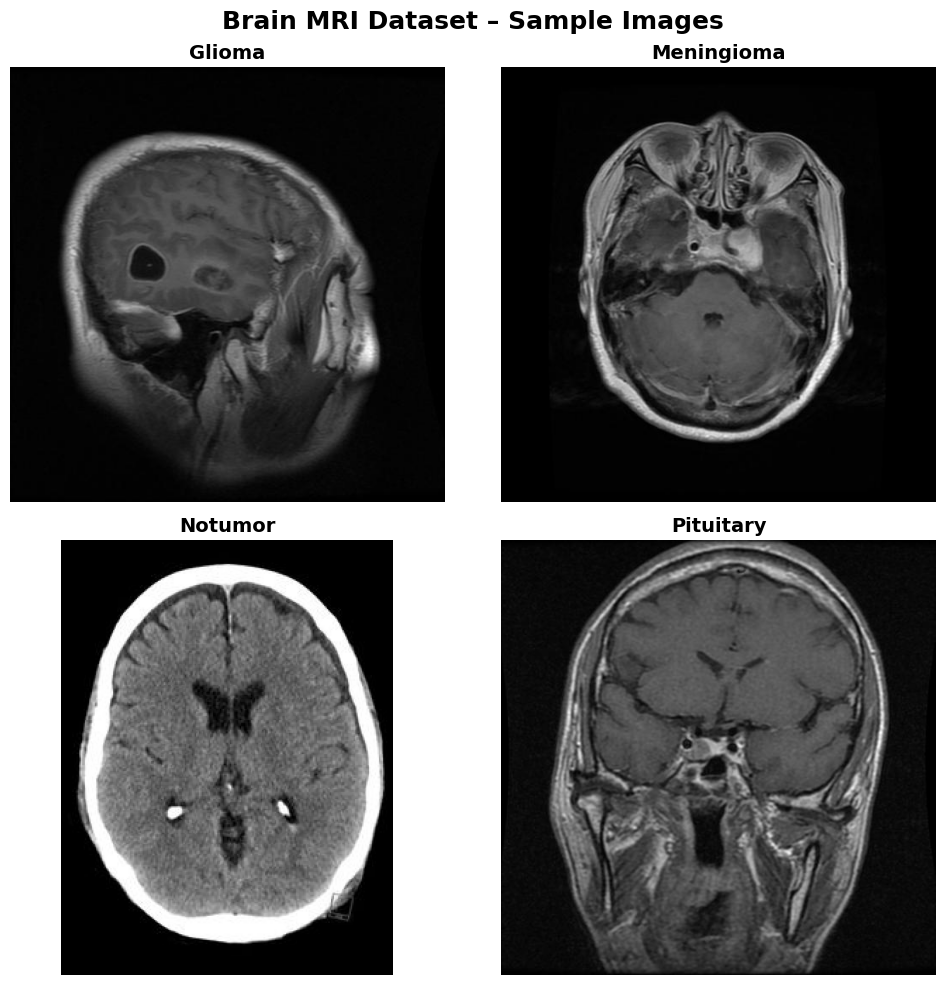

In [21]:
# ============================================================
# VISUALIZE ONE MRI IMAGE FROM EACH CLASS
# ============================================================

import os
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------

classes = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# ------------------------------------------------------------
# Choose dataset split
# ------------------------------------------------------------

# Use Testing to visualize test images.
# Change to TRAIN_DIR if you want training images.

IMAGE_DIR = TEST_DIR

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 10)
)

# ------------------------------------------------------------
# Load one image from each class
# ------------------------------------------------------------

for ax, class_name in zip(
    axes.ravel(),
    classes
):

    # Class folder
    class_path = IMAGE_DIR / class_name

    # Check folder exists
    if not class_path.exists():

        ax.set_title(
            f"{class_name}\nFolder not found"
        )

        ax.axis("off")

        continue

    # Find image files
    files = [
        f for f in class_path.iterdir()
        if f.is_file()
        and f.suffix.lower() in {
            ".jpg",
            ".jpeg",
            ".png",
            ".bmp",
            ".webp"
        }
    ]

    # Check images exist
    if not files:

        ax.set_title(
            f"{class_name}\nNo images found"
        )

        ax.axis("off")

        continue

    # Select first image
    image_path = files[0]

    # Open image
    image = Image.open(
        image_path
    ).convert("RGB")

    # Display
    ax.imshow(image)

    ax.set_title(
        class_name.capitalize(),
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.suptitle(
    "Brain MRI Dataset – Sample Images",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [23]:
# ============================================================
# ANALYZE ORIGINAL IMAGE DIMENSIONS
# ============================================================

import pandas as pd
from PIL import Image

# Use the TESTING dataset
IMAGE_DIR = TEST_DIR

# Store dimensions
dimensions = []

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# ------------------------------------------------------------
# Collect image dimensions
# ------------------------------------------------------------

for class_name in classes:

    class_path = IMAGE_DIR / class_name

    if not class_path.exists():
        print(f"⚠️ Folder not found: {class_path}")
        continue

    for image_path in class_path.iterdir():

        if (
            image_path.is_file()
            and image_path.suffix.lower()
            in IMAGE_EXTENSIONS
        ):

            try:

                with Image.open(image_path) as image:

                    width, height = image.size

                    dimensions.append({
                        "class": class_name,
                        "width": width,
                        "height": height
                    })

            except Exception as e:

                print(
                    f"⚠️ Could not read "
                    f"{image_path.name}: {e}"
                )


# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

dimensions = pd.DataFrame(dimensions)

print(
    f"Total images analyzed: "
    f"{len(dimensions):,}"
)

dimensions.head()

Total images analyzed: 1,311


,class,width,height
0,glioma,512,512
1,glioma,512,512
2,glioma,512,512
3,glioma,512,512
4,glioma,512,512


In [25]:
# ============================================================
# IMAGE COUNT BY CLASS
# ============================================================

class_counts = (
    dimensions["class"]
    .value_counts()
    .reindex(classes)
)

class_counts

class
glioma        300
meningioma    306
notumor       405
pituitary     300
Name: count, dtype: int64

Training Dataset Class Distribution
----------------------------------------
glioma         : 1,321
meningioma     : 1,339
notumor        : 1,595
pituitary      : 1,457


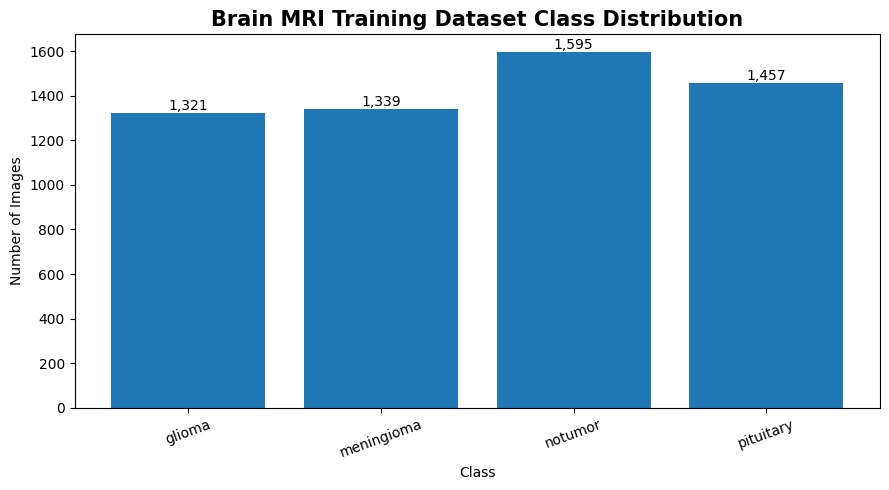

In [27]:
# ============================================================
# TRAINING CLASS DISTRIBUTION
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

# Use the training split
IMAGE_DIR = TRAIN_DIR

counts = {}

for class_name in classes:

    class_path = IMAGE_DIR / class_name

    if not class_path.exists():
        print(f"⚠️ Folder not found: {class_path}")
        counts[class_name] = 0
        continue

    counts[class_name] = sum(
        1
        for file in class_path.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )


# ------------------------------------------------------------
# Display counts
# ------------------------------------------------------------

print("Training Dataset Class Distribution")
print("-" * 40)

for class_name, count in counts.items():
    print(f"{class_name:<15}: {count:,}")


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    counts.keys(),
    counts.values()
)

plt.title(
    "Brain MRI Training Dataset Class Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=20)

# Add values above bars
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()